# Spoken Grammar Scoring from Audio

**Goal:** predict a grammar score (1–5, per the rubric) from a speech recording (`.wav`).
**Metrics:** Pearson correlation and RMSE (leaderboard); training RMSE is reported explicitly below as required.

## Approach (summary)
Grammar is a property of *what* is said and *how fluently* it is produced, so the pipeline uses three complementary views of each recording:

1. **ASR transcript → text features** – Whisper transcribes the audio; from the transcript we compute grammar-error counts (LanguageTool), GPT-2 perplexity (fluency / well-formedness), sentence/word statistics, filler and repetition counts, and sentence embeddings.
2. **Acoustic-fluency features** – duration, speech rate, pause statistics, MFCC statistics.
3. **Self-supervised speech embeddings** – mean-pooled wav2vec2 hidden states (captures hesitations, disfluency, proficiency cues that ASR text loses).

Several regressors (Ridge, SVR, gradient boosting) are trained with stratified 5-fold CV, their out-of-fold predictions are blended with non-negative linear regression, and the final blend is clipped to [1, 5].

## 0. Setup

In [8]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.makedirs('/content/drive/MyDrive/grammar_cache_v2', exist_ok=True)
if not os.path.exists('/content/cache_v2'):
    os.symlink('/content/drive/MyDrive/grammar_cache_v2', '/content/cache_v2')

Mounted at /content/drive


In [9]:
!pip -q install transformers librosa soundfile sentence-transformers language_tool_python seaborn

In [11]:
import os, kagglehub
kagglehub.login()    # a box appears: paste your Kaggle API token
path = kagglehub.competition_download('shl-hiring-assessment-2026')
os.environ["DATA_DIR"] = path
print(path)

/root/.cache/kagglehub/competitions/shl-hiring-assessment-2026
Kaggle credentials set.
Kaggle credentials successfully validated.


In [12]:
import os, re, glob, json, warnings, random
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch, librosa
from tqdm.auto import tqdm
from scipy.stats import pearsonr

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
SR = 16000                                   # sampling rate expected by Whisper / wav2vec2
CACHE = Path("cache_v2"); CACHE.mkdir(exist_ok=True)   # features are cached so re-runs are fast
print("Device:", DEVICE)

Device: cuda


## 1. Load data

In [13]:
# Locate the competition files automatically (set DATA_DIR env var to override)
def find_first(name, roots):
    for r in roots:
        hits = glob.glob(os.path.join(r, "**", name), recursive=True)
        if hits:
            return hits[0]
    raise FileNotFoundError(f"{name} not found under {roots}")

ROOTS = [os.environ.get("DATA_DIR", "."), "/kaggle/input", "."]
TRAIN_CSV  = find_first("train.csv", ROOTS)
TEST_CSV   = find_first("test.csv", ROOTS)
SAMPLE_CSV = find_first("sample_submission.csv", ROOTS)
DATA_DIR   = Path(TRAIN_CSV).parent

train  = pd.read_csv(TRAIN_CSV)
test   = pd.read_csv(TEST_CSV)
sample = pd.read_csv(SAMPLE_CSV)

FILE_COL, LABEL_COL = train.columns[0], train.columns[1]
TEST_FILE_COL = test.columns[0]
print("train columns:", list(train.columns), "| test columns:", list(test.columns))
print("sample submission columns:", list(sample.columns))

# Index wav files by (folder, name): train/ and test/ contain DIFFERENT files with the SAME names,
# so a lookup by name alone would silently read the wrong audio.
def index_wavs(root):
    return {(Path(p).parent.name.lower(), Path(p).stem): p
            for p in glob.glob(os.path.join(root, "**", "*.wav"), recursive=True)}

wavs = index_wavs(DATA_DIR)
if not wavs:
    for r in ROOTS:
        wavs = index_wavs(r)
        if wavs: break
print("wav files found:", len(wavs))

train["path"] = train[FILE_COL].astype(str).map(lambda s: wavs.get(("train", Path(s).stem)))
test["path"]  = test[TEST_FILE_COL].astype(str).map(lambda s: wavs.get(("test", Path(s).stem)))
assert train["path"].notna().all() and test["path"].notna().all(), \
    "Some audio files are missing - check that the wavs sit in folders named 'train' and 'test'"
assert not set(train["path"]) & set(test["path"]), "train and test point to the same audio file"

# One combined frame so every feature is extracted identically for train and test
df_all = pd.concat([
    pd.DataFrame({"file": train[FILE_COL].astype(str), "path": train["path"], "split": "train"}),
    pd.DataFrame({"file": test[TEST_FILE_COL].astype(str), "path": test["path"], "split": "test"}),
], ignore_index=True)
n_train = len(train)
y = train[LABEL_COL].values.astype(float)
print(f"train={n_train}  test={len(test)}")
train.head()

train columns: ['filename', 'label'] | test columns: ['filename', 'label']
sample submission columns: ['filename', 'label']
wav files found: 985
train=769  test=216


,filename,label,path
0,audio_192.wav,3.0,/root/.cache/kagglehub/competitions/shl-hiring...
1,audio_436.wav,3.0,/root/.cache/kagglehub/competitions/shl-hiring...
2,audio_447.wav,3.5,/root/.cache/kagglehub/competitions/shl-hiring...
3,audio_126.wav,2.0,/root/.cache/kagglehub/competitions/shl-hiring...
4,audio_61.wav,2.0,/root/.cache/kagglehub/competitions/shl-hiring...


## 2. Exploratory analysis

durations:   0%|          | 0/985 [00:00<?, ?it/s]

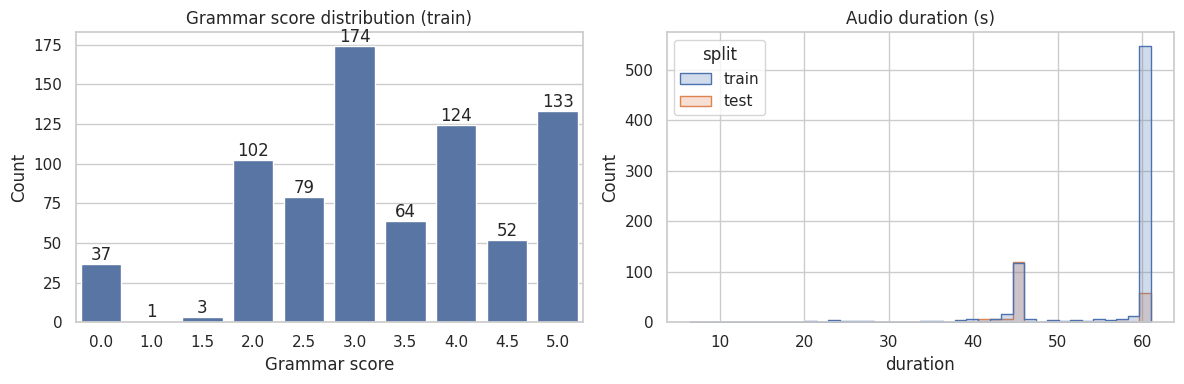

count    769.000000
mean       3.313394
std        1.239000
min        0.000000
25%        2.500000
50%        3.000000
75%        4.000000
max        5.000000
Name: label, dtype: float64
Baseline RMSE if we always predict the mean: 1.2382


In [14]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=LABEL_COL, data=train, ax=ax[0], color="#4C72B0")
ax[0].set_title("Grammar score distribution (train)")
ax[0].set_xlabel("Grammar score"); ax[0].set_ylabel("Count")
for p in ax[0].patches:
    ax[0].annotate(int(p.get_height()), (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

durations = np.array([librosa.get_duration(path=p) for p in tqdm(df_all["path"], desc="durations")])
df_all["duration"] = durations
sns.histplot(df_all, x="duration", hue="split", bins=40, ax=ax[1], element="step")
ax[1].set_title("Audio duration (s)")
plt.tight_layout(); plt.show()
print(train[LABEL_COL].describe())
print("Baseline RMSE if we always predict the mean:", np.sqrt(np.mean((y - y.mean()) ** 2)).round(4))

## 3. Feature extraction

### 3.1 Whisper transcripts
Transcripts are cached to `cache/transcripts.csv`.
*Caveat:* Whisper has a strong language model and sometimes "repairs" ungrammatical speech. To compensate, we also keep audio-level wav2vec2 embeddings that see the raw signal, and use model-ensembling.

In [15]:
from transformers import pipeline

TRANSCRIPT_FILE = CACHE / "transcripts.csv"
WHISPER_MODEL = "openai/whisper-small"      # use whisper-base for speed or whisper-medium for accuracy

def load_audio(path, max_sec=None):
    wav, _ = librosa.load(path, sr=SR, mono=True)
    return wav[: int(max_sec * SR)] if max_sec else wav

if TRANSCRIPT_FILE.exists():
    transcripts = pd.read_csv(TRANSCRIPT_FILE)["text"].fillna("").tolist()
else:
    asr = pipeline("automatic-speech-recognition", model=WHISPER_MODEL, device=0 if DEVICE == "cuda" else -1,
                   chunk_length_s=30, torch_dtype=torch.float16 if DEVICE == "cuda" else torch.float32)
    transcripts, B = [], 16
    for i in tqdm(range(0, len(df_all), B), desc="Whisper ASR"):
        batch = [{"raw": load_audio(p), "sampling_rate": SR} for p in df_all["path"].iloc[i:i + B]]
        out = asr(batch, batch_size=B, generate_kwargs={"language": "en", "task": "transcribe"})
        transcripts += [o["text"].strip() for o in out]
    pd.DataFrame({"file": df_all["file"], "text": transcripts}).to_csv(TRANSCRIPT_FILE, index=False)
    del asr
df_all["text"] = transcripts
df_all.loc[:4, ["file", "text"]]

Loading weights:   0%|          | 0/479 [00:00<?, ?it/s]

[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on its own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).


Whisper ASR:   0%|          | 0/62 [00:00<?, ?it/s]

[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


,file,text
0,audio_192.wav,"The playground is very, very beautiful and fun..."
1,audio_436.wav,The scene of a school playground. Our playgrou...
2,audio_447.wav,My favorite place to visit is the beach. I lov...
3,audio_126.wav,"Once upon a time, we, with five friends, went ..."
4,audio_61.wav,"Well, when I was a child, I remember I went to..."


### 3.2 Text features (grammar errors, perplexity, fluency statistics)

In [16]:
FILLERS = {"um", "uh", "er", "erm", "ah", "hmm", "like", "you know", "i mean", "so"}

def basic_text_feats(text, duration):
    t = text.strip()
    words = re.findall(r"[A-Za-z']+", t.lower())
    n = len(words)
    sents = [s for s in re.split(r"[.!?]+", t) if s.strip()]
    rep = sum(1 for a, b in zip(words, words[1:]) if a == b)          # immediate word repetitions
    return {
        "n_words": n,
        "n_sents": len(sents),
        "avg_sent_len": n / max(len(sents), 1),
        "avg_word_len": np.mean([len(w) for w in words]) if n else 0,
        "ttr": len(set(words)) / max(n, 1),                              # type-token ratio (lexical variety)
        "n_fillers": sum(w in FILLERS for w in words),
        "n_repeats": rep,
        "words_per_sec": n / max(duration, 1e-3),
        "n_commas": t.count(","),
        "long_words": sum(len(w) >= 7 for w in words) / max(n, 1),
    }

basic = pd.DataFrame([basic_text_feats(t, d) for t, d in zip(df_all["text"], df_all["duration"])])
basic.describe().T[["mean", "std", "min", "max"]]

,mean,std,min,max
n_words,105.537056,68.141210,8.000000,1108.000000
n_sents,5.953299,11.997707,1.000000,225.000000
avg_sent_len,31.084506,31.200018,1.093333,485.000000
avg_word_len,4.223647,0.419996,2.916803,5.875000
ttr,0.601520,0.116446,0.028881,1.000000
n_fillers,1.830457,5.051834,0.000000,142.000000
n_repeats,1.168528,13.475890,0.000000,221.000000
words_per_sec,1.950618,1.136447,0.349565,18.443708
n_commas,3.902538,12.523662,0.000000,264.000000
long_words,0.165344,0.066399,0.000000,0.500000


In [17]:
# --- LanguageTool grammar-error counts (needs Java; falls back to zeros if unavailable) ---
LT_FILE = CACHE / "lt_feats.csv"
if LT_FILE.exists():
    lt_feats = pd.read_csv(LT_FILE)
else:
    try:
        import language_tool_python
        tool = language_tool_python.LanguageTool("en-US")
        rows = []
        for t in tqdm(df_all["text"], desc="LanguageTool"):
            m = tool.check(t)
            cats = [x.category for x in m]
            rows.append({"lt_errors": len(m),
                         "lt_grammar": sum(c == "GRAMMAR" for c in cats),
                         "lt_typos":   sum(c == "TYPOS" for c in cats),
                         "lt_style":   sum(c in ("STYLE", "REDUNDANCY") for c in cats)})
        lt_feats = pd.DataFrame(rows)
        tool.close()
    except Exception as e:
        print("LanguageTool unavailable -> skipping:", repr(e)[:120])
        lt_feats = pd.DataFrame({"lt_errors": 0, "lt_grammar": 0, "lt_typos": 0, "lt_style": 0}, index=range(len(df_all)))
    lt_feats.to_csv(LT_FILE, index=False)
lt_feats["lt_errors_per_word"] = lt_feats["lt_errors"] / basic["n_words"].clip(lower=1)
lt_feats["lt_grammar_per_word"] = lt_feats["lt_grammar"] / basic["n_words"].clip(lower=1)
lt_feats.describe().T[["mean", "std", "max"]]

LanguageTool:   0%|          | 0/985 [00:00<?, ?it/s]

,mean,std,max
lt_errors,3.017259,6.775187,109.00000
lt_grammar,0.415228,0.729163,4.00000
lt_typos,0.473096,1.177161,11.00000
lt_style,0.104569,0.340715,3.00000
lt_errors_per_word,0.025864,0.027182,0.43083
lt_grammar_per_word,0.004392,0.007846,0.05000


In [18]:
# --- GPT-2 perplexity: low perplexity ~ well-formed, fluent English ---
from transformers import GPT2LMHeadModel, GPT2TokenizerFast
PPL_FILE = CACHE / "ppl.csv"
if PPL_FILE.exists():
    ppl = pd.read_csv(PPL_FILE)
else:
    tok = GPT2TokenizerFast.from_pretrained("gpt2")
    lm = GPT2LMHeadModel.from_pretrained("gpt2").to(DEVICE).eval()
    rows = []
    for t in tqdm(df_all["text"], desc="GPT-2 perplexity"):
        ids = tok(t if t.strip() else tok.eos_token, return_tensors="pt", truncation=True, max_length=256).input_ids.to(DEVICE)
        with torch.no_grad():
            loss = lm(ids, labels=ids).loss.item()
        rows.append({"gpt2_loss": loss, "gpt2_log_ppl": loss, "n_tokens": ids.shape[1]})
    ppl = pd.DataFrame(rows)[["gpt2_loss", "n_tokens"]]
    ppl.to_csv(PPL_FILE, index=False)
    del lm
ppl.describe().T[["mean", "std", "min", "max"]]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

...

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT-2 perplexity:   0%|          | 0/985 [00:00<?, ?it/s]

[transformers] `loss_type=None` was set in the config but it is unrecognized. Using the default loss: `ForCausalLMLoss`.


,mean,std,min,max
gpt2_loss,3.577498,0.700862,0.092127,6.16624
n_tokens,112.881218,36.733177,9.000000,256.00000


In [19]:
# --- Sentence embeddings of the transcript (semantic/syntactic style) ---
SENT_FILE = CACHE / "sent_emb.npy"
try:
    if SENT_FILE.exists():
        X_sent = np.load(SENT_FILE)
    else:
        from sentence_transformers import SentenceTransformer
        st = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=DEVICE)
        X_sent = st.encode(df_all["text"].tolist(), batch_size=64, show_progress_bar=True)
        np.save(SENT_FILE, X_sent)
except Exception as e:
    print("Sentence embeddings skipped:", repr(e)[:120]); X_sent = None
print(None if X_sent is None else X_sent.shape)

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/10.5k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/612 [00:00<?, ?B/s]

...

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

Batches:   0%|          | 0/16 [00:00<?, ?it/s]

(985, 384)


### 3.3 Acoustic / fluency features

In [20]:
AC_FILE = CACHE / "acoustic.csv"
def acoustic_feats(path):
    y_, _ = librosa.load(path, sr=SR, mono=True)
    dur = len(y_) / SR
    mfcc = librosa.feature.mfcc(y=y_, sr=SR, n_mfcc=20)
    f = {f"mfcc{i}_mean": mfcc[i].mean() for i in range(20)}
    f.update({f"mfcc{i}_std": mfcc[i].std() for i in range(20)})
    f["centroid"] = librosa.feature.spectral_centroid(y=y_, sr=SR).mean()
    f["zcr"] = librosa.feature.zero_crossing_rate(y_).mean()
    rms = librosa.feature.rms(y=y_)[0]
    f["rms_mean"], f["rms_std"] = rms.mean(), rms.std()
    # pauses: gaps between non-silent intervals
    iv = librosa.effects.split(y_, top_db=30)
    speech = sum(e - s for s, e in iv) / SR
    gaps = [(iv[i + 1][0] - iv[i][1]) / SR for i in range(len(iv) - 1)]
    f["speech_ratio"] = speech / max(dur, 1e-3)
    f["n_pauses"] = len(gaps)
    f["pauses_per_sec"] = len(gaps) / max(dur, 1e-3)
    f["mean_pause"] = float(np.mean(gaps)) if gaps else 0.0
    f["max_pause"] = float(np.max(gaps)) if gaps else 0.0
    f["long_pauses"] = sum(g > 0.5 for g in gaps)
    return f

if AC_FILE.exists():
    acoustic = pd.read_csv(AC_FILE)
else:
    acoustic = pd.DataFrame([acoustic_feats(p) for p in tqdm(df_all["path"], desc="acoustic")])
    acoustic.to_csv(AC_FILE, index=False)
acoustic.shape

acoustic:   0%|          | 0/985 [00:00<?, ?it/s]

(985, 50)

### 3.4 wav2vec2 embeddings (mean-pooled hidden states from layers 4, 8, 12)

In [21]:
W2V_FILE = CACHE / "w2v.npy"
if W2V_FILE.exists():
    X_w2v = np.load(W2V_FILE)
else:
    from transformers import Wav2Vec2FeatureExtractor, Wav2Vec2Model
    fe = Wav2Vec2FeatureExtractor.from_pretrained("facebook/wav2vec2-base-960h")
    w2v = Wav2Vec2Model.from_pretrained("facebook/wav2vec2-base-960h").to(DEVICE).eval()
    embs = []
    for p in tqdm(df_all["path"], desc="wav2vec2"):
        wav = load_audio(p, max_sec=40)
        inp = fe(wav, sampling_rate=SR, return_tensors="pt").input_values.to(DEVICE)
        with torch.no_grad():
            hs = w2v(inp, output_hidden_states=True).hidden_states
        embs.append(torch.cat([hs[i].mean(1).squeeze(0) for i in (4, 8, 12)]).cpu().numpy())
    X_w2v = np.vstack(embs); np.save(W2V_FILE, X_w2v)
    del w2v
print(X_w2v.shape)

preprocessor_config.json:   0%|          | 0.00/159 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/1.60k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/210 [00:00<?, ?it/s]

[transformers] Wav2Vec2Model LOAD REPORT from: facebook/wav2vec2-base-960h
Key               | Status     | 
------------------+------------+-
lm_head.bias      | UNEXPECTED | 
lm_head.weight    | UNEXPECTED | 
masked_spec_embed | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


wav2vec2:   0%|          | 0/985 [00:00<?, ?it/s]

(985, 2304)


### 3.5 Assemble feature blocks

{'hand': (985, 69), 'w2v': (985, 2304), 'sent': (985, 384)}


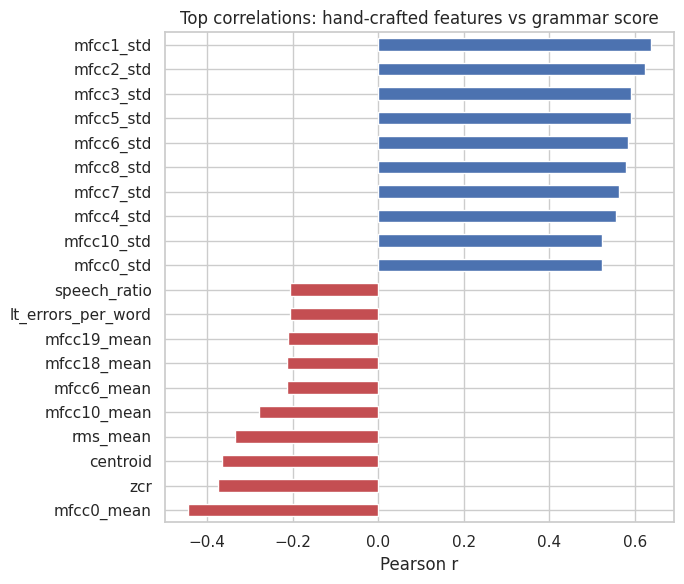

In [22]:
hand_df = pd.concat([df_all[["duration"]], basic, lt_feats, ppl, acoustic], axis=1)
hand_df = hand_df.replace([np.inf, -np.inf], np.nan).fillna(0)
X_hand = hand_df.values.astype(np.float32)

BLOCKS = {"hand": X_hand, "w2v": X_w2v}
if X_sent is not None:
    BLOCKS["sent"] = X_sent
print({k: v.shape for k, v in BLOCKS.items()})

# Which hand-crafted features correlate with the target? (train rows only, Pearson r)
corr = hand_df.iloc[:n_train].apply(lambda c: np.corrcoef(c, y)[0, 1] if c.std() > 0 else 0).sort_values()
top = pd.concat([corr.head(10), corr.tail(10)])
plt.figure(figsize=(7, 6))
top.plot.barh(color=["#C44E52" if v < 0 else "#4C72B0" for v in top])
plt.title("Top correlations: hand-crafted features vs grammar score"); plt.xlabel("Pearson r")
plt.tight_layout(); plt.show()

## 4. Models and cross-validation
Each model gets a subset of the feature blocks. Scaling/PCA live **inside** the sklearn pipeline, so they are fitted only on the training fold (no leakage).
Folds are stratified on the rounded score so every fold sees all grammar levels.

In [23]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import RidgeCV, LinearRegression
from sklearn.svm import SVR
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.model_selection import StratifiedKFold, KFold
from sklearn.metrics import mean_squared_error

def rmse(a, b): return float(np.sqrt(mean_squared_error(a, b)))
def pear(a, b): return float(pearsonr(a, b)[0])

MODEL_SPECS = {
    "Ridge (wav2vec2+hand)": (["w2v", "hand"],
        lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 5, 12)))),
    "SVR (wav2vec2 PCA+hand)": (["w2v", "hand"],
        lambda: make_pipeline(StandardScaler(), PCA(64, random_state=SEED), SVR(C=3, epsilon=0.1))),
    "HistGB (hand)": (["hand"],
        lambda: HistGradientBoostingRegressor(max_iter=300, learning_rate=0.04, max_depth=4,
                                              l2_regularization=1.0, random_state=SEED)),
}
if "sent" in BLOCKS:
    MODEL_SPECS["Ridge (sentence emb+hand)"] = (["sent", "hand"],
        lambda: make_pipeline(StandardScaler(), RidgeCV(alphas=np.logspace(1, 5, 12))))
    MODEL_SPECS["SVR (sentence PCA+hand)"] = (["sent", "hand"],
        lambda: make_pipeline(StandardScaler(), PCA(48, random_state=SEED), SVR(C=3, epsilon=0.1)))

def get_X(names):
    return np.hstack([BLOCKS[n] for n in names])

# Stratified K-fold on the rounded label (fallback to plain KFold for tiny classes)
y_strat = np.round(y).astype(int)
if np.bincount(y_strat - y_strat.min()).min() >= 5:
    splitter = StratifiedKFold(5, shuffle=True, random_state=SEED).split(np.zeros(n_train), y_strat)
else:
    splitter = KFold(5, shuffle=True, random_state=SEED).split(np.zeros(n_train))
folds = list(splitter)

oof, cv_rows = {}, []
for name, (blocks, make) in MODEL_SPECS.items():
    X = get_X(blocks)[:n_train]
    o = np.zeros(n_train)
    for tr, va in folds:
        m = make().fit(X[tr], y[tr])
        o[va] = m.predict(X[va])
    oof[name] = np.clip(o, 1, 5)
    cv_rows.append({"model": name, "CV RMSE": rmse(y, oof[name]), "CV Pearson": pear(y, oof[name])})
cv_table = pd.DataFrame(cv_rows).sort_values("CV RMSE").reset_index(drop=True)
cv_table

,model,CV RMSE,CV Pearson
0,Ridge (wav2vec2+hand),0.639702,0.863341
1,SVR (wav2vec2 PCA+hand),0.663520,0.849784
2,HistGB (hand),0.725444,0.817912
3,Ridge (sentence emb+hand),0.739267,0.805748
4,SVR (sentence PCA+hand),0.796370,0.774206


### 4.1 Blend the models (non-negative linear stacking on out-of-fold predictions)

Blend weights: {'Ridge (wav2vec2+hand)': np.float64(0.333), 'SVR (wav2vec2 PCA+hand)': np.float64(0.243), 'HistGB (hand)': np.float64(0.194), 'Ridge (sentence emb+hand)': np.float64(0.199), 'SVR (sentence PCA+hand)': np.float64(0.032)}
Blend  CV RMSE = 0.6142 | CV Pearson = 0.8879


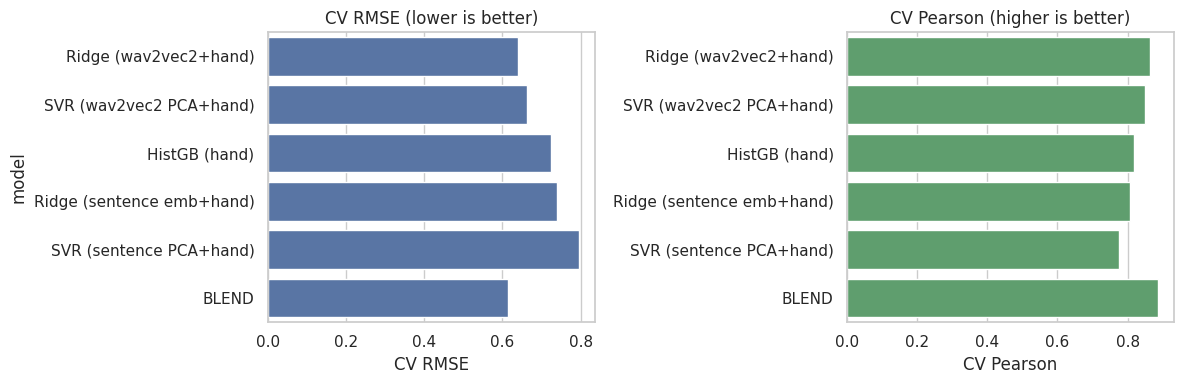

In [24]:
names = list(oof)
O = np.column_stack([oof[n] for n in names])
blender = LinearRegression(positive=True).fit(O, y)
weights = blender.coef_ / blender.coef_.sum()
oof_blend = np.clip(O @ weights, 1, 5)
print("Blend weights:", dict(zip(names, weights.round(3))))
print(f"Blend  CV RMSE = {rmse(y, oof_blend):.4f} | CV Pearson = {pear(y, oof_blend):.4f}")
# (weights are fitted on the same OOF predictions, so this is very slightly optimistic; with <=5 weights the effect is tiny)

cv_table = pd.concat([cv_table, pd.DataFrame([{"model": "BLEND", "CV RMSE": rmse(y, oof_blend), "CV Pearson": pear(y, oof_blend)}])],
                     ignore_index=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.barplot(data=cv_table, y="model", x="CV RMSE", ax=ax[0], color="#4C72B0"); ax[0].set_title("CV RMSE (lower is better)")
sns.barplot(data=cv_table, y="model", x="CV Pearson", ax=ax[1], color="#55A868"); ax[1].set_title("CV Pearson (higher is better)")
ax[1].set_ylabel("")
plt.tight_layout(); plt.show()

## 5. Final fit, training RMSE and test predictions

In [25]:
train_pred_parts, test_pred_parts = [], []
for name in names:
    blocks, make = MODEL_SPECS[name]
    X = get_X(blocks)
    m = make().fit(X[:n_train], y)                 # refit on ALL training data
    train_pred_parts.append(np.clip(m.predict(X[:n_train]), 1, 5))
    test_pred_parts.append(np.clip(m.predict(X[n_train:]), 1, 5))

train_pred = np.clip(np.column_stack(train_pred_parts) @ weights, 1, 5)
test_pred  = np.clip(np.column_stack(test_pred_parts)  @ weights, 1, 5)

TRAIN_RMSE = rmse(y, train_pred)
TRAIN_PEARSON = pear(y, train_pred)
print("=" * 55)
print(f"  TRAINING RMSE (final blend, in-sample) : {TRAIN_RMSE:.4f}")
print(f"  Training Pearson                      : {TRAIN_PEARSON:.4f}")
print(f"  Cross-validated RMSE  (out-of-fold)   : {rmse(y, oof_blend):.4f}")
print(f"  Cross-validated Pearson (out-of-fold) : {pear(y, oof_blend):.4f}")
print("=" * 55)
print("Note: training RMSE is optimistic (model has seen these rows); CV RMSE is the honest estimate of test error.")

  TRAINING RMSE (final blend, in-sample) : 0.3745
  Training Pearson                      : 0.9735
  Cross-validated RMSE  (out-of-fold)   : 0.6142
  Cross-validated Pearson (out-of-fold) : 0.8879
Note: training RMSE is optimistic (model has seen these rows); CV RMSE is the honest estimate of test error.


## 6. Result visualisations

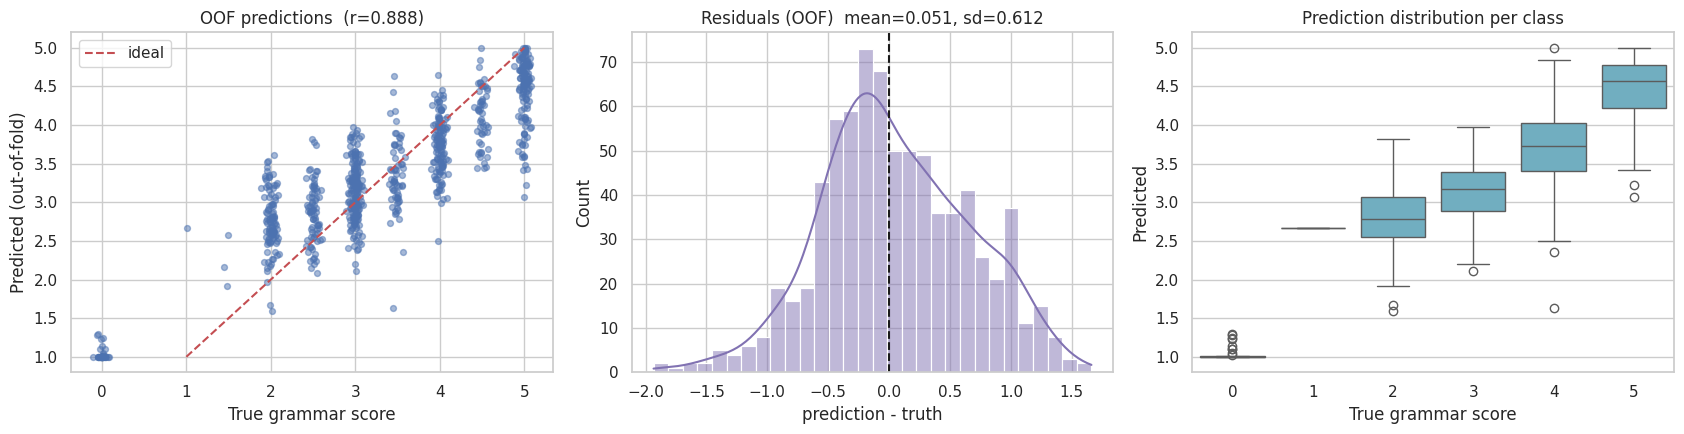

In [26]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.5))

# (a) predicted vs actual (OOF)
jit = np.random.RandomState(0).normal(0, 0.04, n_train)
ax[0].scatter(y + jit, oof_blend, alpha=0.5, s=18)
ax[0].plot([1, 5], [1, 5], "r--", label="ideal")
ax[0].set_xlabel("True grammar score"); ax[0].set_ylabel("Predicted (out-of-fold)")
ax[0].set_title(f"OOF predictions  (r={pear(y, oof_blend):.3f})"); ax[0].legend()

# (b) residuals
res = oof_blend - y
sns.histplot(res, bins=30, kde=True, ax=ax[1], color="#8172B2")
ax[1].axvline(0, color="k", ls="--"); ax[1].set_title(f"Residuals (OOF)  mean={res.mean():.3f}, sd={res.std():.3f}")
ax[1].set_xlabel("prediction - truth")

# (c) prediction spread per true class
sns.boxplot(x=np.round(y).astype(int), y=oof_blend, ax=ax[2], color="#64B5CD")
ax[2].set_xlabel("True grammar score"); ax[2].set_ylabel("Predicted"); ax[2].set_title("Prediction distribution per class")
plt.tight_layout(); plt.show()

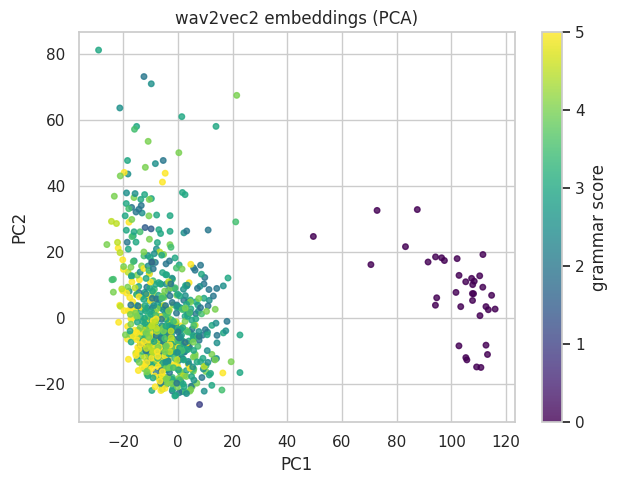

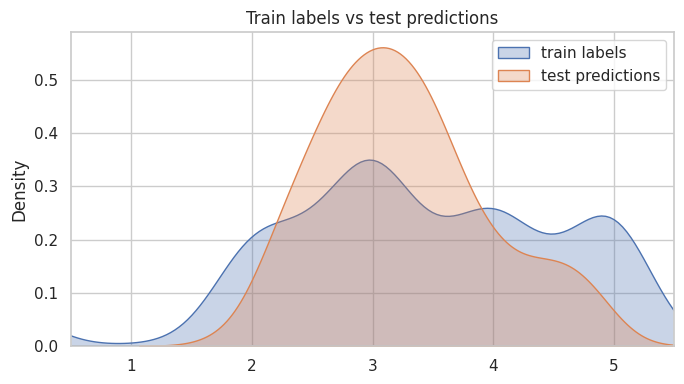

In [27]:
# 2-D view of the wav2vec2 embedding space coloured by grammar score
from sklearn.decomposition import PCA as _PCA
Z = _PCA(2, random_state=SEED).fit_transform(StandardScaler().fit_transform(X_w2v[:n_train]))
plt.figure(figsize=(6.5, 5))
sc = plt.scatter(Z[:, 0], Z[:, 1], c=y, cmap="viridis", s=16, alpha=0.8)
plt.colorbar(sc, label="grammar score"); plt.title("wav2vec2 embeddings (PCA)"); plt.xlabel("PC1"); plt.ylabel("PC2")
plt.tight_layout(); plt.show()

# Distribution of test predictions vs. training labels (sanity check for distribution shift)
plt.figure(figsize=(7, 4))
sns.kdeplot(y, label="train labels", fill=True, alpha=0.3)
sns.kdeplot(test_pred, label="test predictions", fill=True, alpha=0.3)
plt.xlim(0.5, 5.5); plt.legend(); plt.title("Train labels vs test predictions"); plt.tight_layout(); plt.show()

## 7. Write the submission file

In [28]:
# test.csv is the true list of files to predict (sample_submission only provides the column names / format)
sub = pd.DataFrame({sample.columns[0]: test[TEST_FILE_COL].values,
                    sample.columns[1]: test_pred})
assert sub[sub.columns[1]].notna().all() and len(sub) == len(test)
sub.to_csv("submission.csv", index=False)
print(sub.shape); sub.head()

(216, 2)


,filename,label
0,audio_128.wav,3.049748
1,audio_156.wav,4.329998
2,audio_19.wav,4.441707
3,audio_108.wav,2.155235
4,audio_206.wav,2.664757


## 8. Report

### Problem
Predict a 1–5 grammar proficiency score from a speech recording. Metrics: Pearson correlation and RMSE.

### Preprocessing
* All audio resampled to 16 kHz mono.
* Whisper (`whisper-small`) produces an English transcript for every file (30 s chunking for long clips).
* Missing/inf feature values are replaced with 0; scaling and PCA are performed inside the CV pipelines to avoid leakage.
* Predictions are clipped to the valid score range [1, 5].

### Pipeline architecture
```
 wav ──► Whisper ASR ──► transcript ─┬─► LanguageTool errors, GPT-2 perplexity, word/sentence stats  ┐
   │                                 └─► MiniLM sentence embedding                                  │
   ├────► librosa: MFCC, pauses, speech-rate, energy ───────────────────────────────────────────────┼─► Ridge / SVR / HistGB
   └────► wav2vec2 (layers 4/8/12, mean-pooled) ───────────────────────────────────────────────────┘        │
                                                                                         non-negative blend ─► clip[1,5] ─► submission.csv
```

### Evaluation
* **Training RMSE** (compulsory item) is printed in Section 5 (`TRAIN_RMSE`) together with training Pearson.
* **Out-of-fold RMSE / Pearson** (stratified 5-fold CV) are printed in Sections 4–5 and are the reliable estimate of leaderboard performance; training RMSE will be lower because the model has seen those rows.
* Per-model comparison, predicted-vs-true scatter, residuals, per-class boxplots and embedding projections are shown in Sections 3–6.

### Interpretation and limitations
* Error-count / perplexity features and pause/speech-rate features correlate most strongly with the score (see correlation bar plot); wav2vec2 embeddings add proficiency cues that transcripts miss.
* Regression models shrink towards the mean, so extreme scores (1 and 5) are typically under-predicted – visible in the per-class boxplot.
* Whisper may silently "correct" ungrammatical speech, weakening text-based error counts; using the raw-signal wav2vec2 branch and ensembling mitigates this.

### Ideas to improve further
Use `whisper-medium`/`large` or a verbatim ASR (e.g. wav2vec2-CTC transcripts) for disfluency-faithful text; fine-tune wav2vec2/HuBERT end-to-end with an MSE head; add a fine-tuned DeBERTa text regressor on the transcripts; tune blend weights with nested CV.